<a href="https://colab.research.google.com/github/aji405/Machine-learning-/blob/main/ML_exp_1_20.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Training Data:
['Sunny', 'Warm', 'Normal', 'Strong', 'Warm', 'Same', 'Yes']
['Sunny', 'Warm', 'High', 'Strong', 'Warm', 'Same', 'Yes']
['Rainy', 'Cold', 'High', 'Strong', 'Warm', 'Change', 'No']
['Sunny', 'Warm', 'High', 'Strong', 'Cool', 'Change', 'Yes']

Most Specific Hypothesis: ['Sunny', 'Warm', '?', 'Strong', '?', '?']


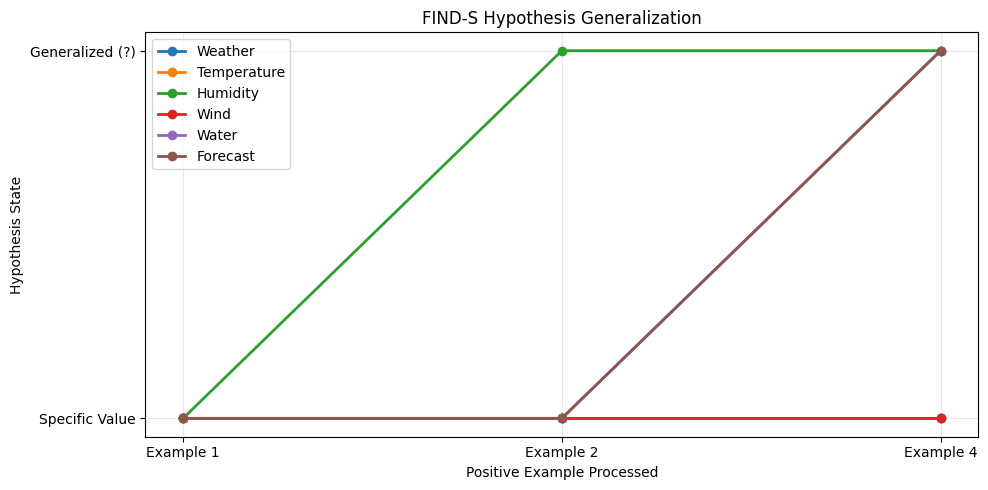

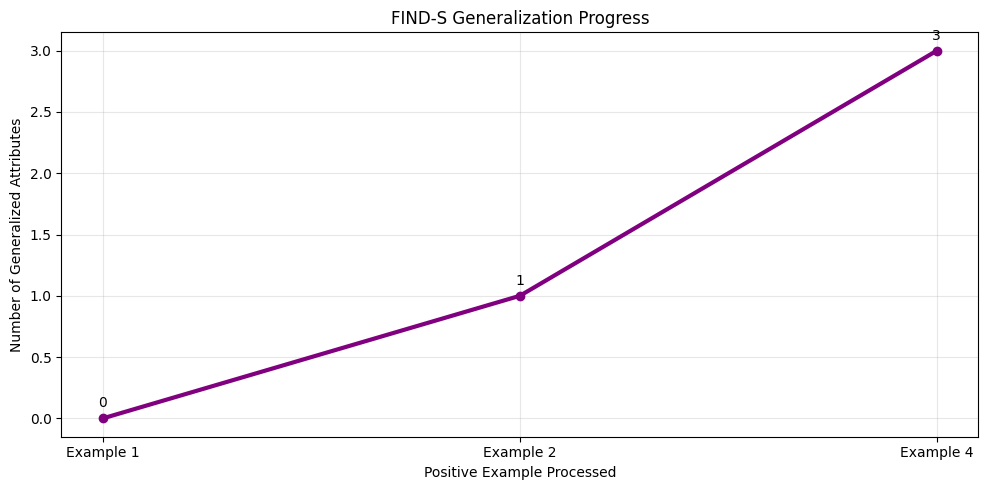

In [4]:
import matplotlib.pyplot as plt

# Training dataset
data = [
    ["Sunny", "Warm", "Normal", "Strong", "Warm", "Same", "Yes"],
    ["Sunny", "Warm", "High", "Strong", "Warm", "Same", "Yes"],
    ["Rainy", "Cold", "High", "Strong", "Warm", "Change", "No"],
    ["Sunny", "Warm", "High", "Strong", "Cool", "Change", "Yes"]
]

attributes = ["Weather", "Temperature", "Humidity",
              "Wind", "Water", "Forecast"]

# FIND-S algorithm
S = None
history = []
labels = []

for i, row in enumerate(data, start=1):
    x = row[:-1]
    target = row[-1]

    if target == "Yes":
        if S is None:
            S = x.copy()
        else:
            for j in range(len(S)):
                if S[j] != x[j]:
                    S[j] = "?"

        history.append(S.copy())
        labels.append("Example " + str(i))

print("Training Data:")
for row in data:
    print(row)

print("\nMost Specific Hypothesis:", S)

# Graph 1: Hypothesis Generalization
plt.figure(figsize=(10, 5))

for j, name in enumerate(attributes):
    y = [1 if h[j] == "?" else 0 for h in history]
    plt.plot(labels, y, marker="o", linewidth=2, label=name)

plt.yticks([0, 1], ["Specific Value", "Generalized (?)"])
plt.xlabel("Positive Example Processed")
plt.ylabel("Hypothesis State")
plt.title("FIND-S Hypothesis Generalization")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Graph 2: Generalization Progress
counts = [h.count("?") for h in history]

plt.figure(figsize=(10, 5))
plt.plot(labels, counts, marker="o",
         color="purple", linewidth=3)

for i, count in enumerate(counts):
    plt.annotate(str(count), (i, count),
                 textcoords="offset points",
                 xytext=(0, 8), ha="center")

plt.xlabel("Positive Example Processed")
plt.ylabel("Number of Generalized Attributes")
plt.title("FIND-S Generalization Progress")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Specific Boundary (S): ('Sunny', 'Warm', '?', 'Strong', '?', '?')

General Boundary (G):
('Sunny', '?', '?', '?', '?', '?')
('?', 'Warm', '?', '?', '?', '?')


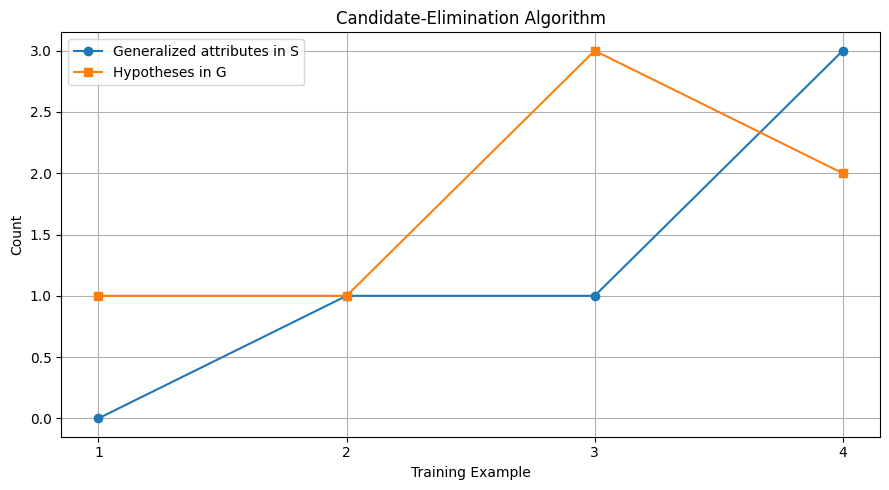

In [3]:

import csv
import matplotlib.pyplot as plt

# Create CSV file
data = [
    ["Sky", "AirTemp", "Humidity", "Wind", "Water", "Forecast", "EnjoySport"],
    ["Sunny", "Warm", "Normal", "Strong", "Warm", "Same", "Yes"],
    ["Sunny", "Warm", "High", "Strong", "Warm", "Same", "Yes"],
    ["Rainy", "Cold", "High", "Strong", "Warm", "Change", "No"],
    ["Sunny", "Warm", "High", "Strong", "Cool", "Change", "Yes"]
]

with open("training.csv", "w", newline="") as f:
    csv.writer(f).writerows(data)

with open("training.csv", "r") as f:
    rows = list(csv.reader(f))

examples = rows[1:]
attributes = rows[0][:-1]
n = len(attributes)
domains = [set(row[i] for row in examples) for i in range(n)]

S = tuple("Ø" for _ in range(n))
G = [tuple("?" for _ in range(n))]

def covers(h, x):
    return all(a == "?" or a == b for a, b in zip(h, x))

def more_general(h1, h2):
    return all(a == "?" or a == b or b == "Ø"
               for a, b in zip(h1, h2))

def generalize(h, x):
    return tuple(x[i] if h[i] == "Ø" else
                 h[i] if h[i] == x[i] or h[i] == "?" else "?"
                 for i in range(n))

def specialize(h, x):
    result = []
    for i in range(n):
        if h[i] == "?":
            for value in domains[i]:
                if value != x[i]:
                    new_h = list(h)
                    new_h[i] = value
                    candidate = tuple(new_h)
                    if more_general(candidate, S):
                        result.append(candidate)
    return result

history = []

for row in examples:
    x, target = row[:-1], row[-1]

    if target == "Yes":
        G = [g for g in G if covers(g, x)]
        if not covers(S, x):
            S = generalize(S, x)
        G = [g for g in G if more_general(g, S)]

    else:
        new_G = []
        for g in G:
            if covers(g, x):
                new_G.extend(specialize(g, x))
            else:
                new_G.append(g)

        G = list(set(new_G))
        G = [g for g in G if more_general(g, S)]

    history.append((S, G.copy()))

print("Specific Boundary (S):", S)
print("\nGeneral Boundary (G):")
for g in G:
    print(g)

# Plot boundary progress
plt.figure(figsize=(9, 5))
plt.plot(range(1, len(history) + 1),
         [sum(v == "?" for v in s) for s, g in history],
         marker="o", label="Generalized attributes in S")
plt.plot(range(1, len(history) + 1),
         [len(g) for s, g in history],
         marker="s", label="Hypotheses in G")

plt.xlabel("Training Example")
plt.ylabel("Count")
plt.title("Candidate-Elimination Algorithm")
plt.xticks(range(1, len(history) + 1))
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


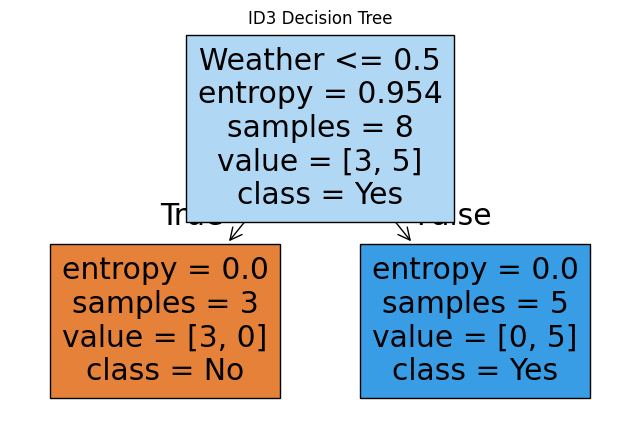

New Sample: Rainy
Prediction: Yes


In [5]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Dataset
data = {
    'Weather': ['Sunny', 'Sunny', 'Rainy', 'Rainy',
                'Overcast', 'Overcast', 'Sunny', 'Rainy'],
    'Play':    ['No', 'No', 'Yes', 'Yes',
                'Yes', 'Yes', 'No', 'Yes']
}

df = pd.DataFrame(data)

# Convert text into numbers
df['Weather'] = df['Weather'].map(
    {'Sunny': 0, 'Rainy': 1, 'Overcast': 2}
)
df['Play'] = df['Play'].map({'No': 0, 'Yes': 1})

# Build decision tree using entropy
X = df[['Weather']]
y = df['Play']

model = DecisionTreeClassifier(criterion='entropy', random_state=0)
model.fit(X, y)

# Display decision tree
plt.figure(figsize=(8, 5))
plot_tree(model, feature_names=['Weather'],
          class_names=['No', 'Yes'], filled=True)
plt.title("ID3 Decision Tree")
plt.show()

# Classify a new sample: Rainy weather
sample = pd.DataFrame({'Weather': [1]})
prediction = model.predict(sample)

print("New Sample: Rainy")
print("Prediction:", "Yes" if prediction[0] == 1 else "No")


Actual Output:    [0 1 1 0]
Predicted Output: [0 1 1 0]
Accuracy: 100.0 %


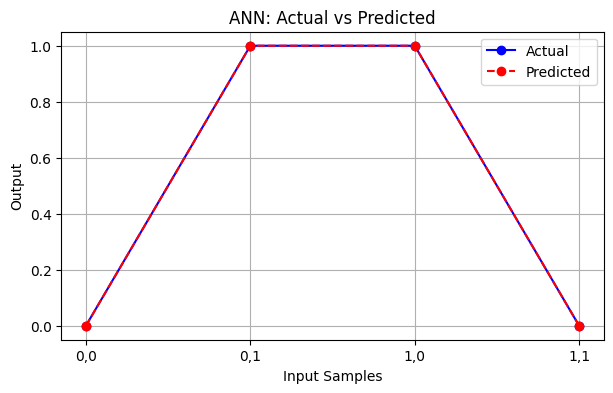

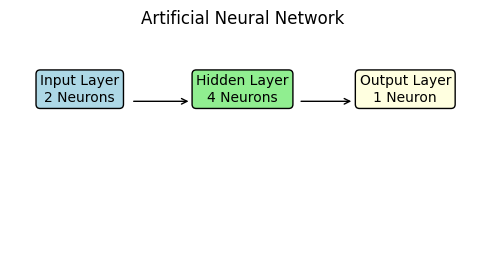

In [6]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

# Dataset: XOR problem
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y = np.array([0, 1, 1, 0])

# Build ANN using Backpropagation
model = MLPClassifier(
    hidden_layer_sizes=(4,),
    activation='tanh',
    solver='lbfgs',
    max_iter=5000,
    random_state=1
)

# Train the model
model.fit(X, y)

# Test the model
pred = model.predict(X)

print("Actual Output:   ", y)
print("Predicted Output:", pred)
print("Accuracy:", accuracy_score(y, pred) * 100, "%")

# Plot 1: Actual vs Predicted output
plt.figure(figsize=(7, 4))
plt.plot(range(4), y, 'bo-', label="Actual")
plt.plot(range(4), pred, 'ro--', label="Predicted")
plt.xticks(range(4), ['0,0', '0,1', '1,0', '1,1'])
plt.xlabel("Input Samples")
plt.ylabel("Output")
plt.title("ANN: Actual vs Predicted")
plt.legend()
plt.grid(True)
plt.show()

# Plot 2: Neural network structure
plt.figure(figsize=(6, 3))
plt.axis('off')
plt.text(0.15, 0.7, "Input Layer\n2 Neurons",
         ha='center', bbox=dict(boxstyle='round', facecolor='lightblue'))
plt.text(0.5, 0.7, "Hidden Layer\n4 Neurons",
         ha='center', bbox=dict(boxstyle='round', facecolor='lightgreen'))
plt.text(0.85, 0.7, "Output Layer\n1 Neuron",
         ha='center', bbox=dict(boxstyle='round', facecolor='lightyellow'))
plt.annotate("", xy=(0.39, 0.7), xytext=(0.26, 0.7),
             arrowprops=dict(arrowstyle='->'))
plt.annotate("", xy=(0.74, 0.7), xytext=(0.62, 0.7),
             arrowprops=dict(arrowstyle='->'))
plt.title("Artificial Neural Network")
plt.show()


New Sample: [4, 4]
Predicted Class: 0


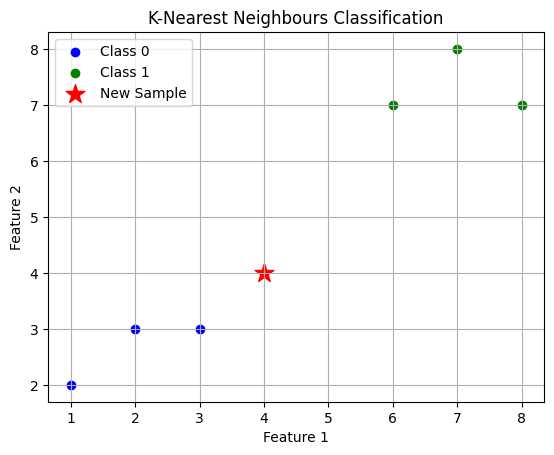

In [7]:

import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier

# Dataset
X = [[1, 2], [2, 3], [3, 3],
     [6, 7], [7, 8], [8, 7]]
y = [0, 0, 0, 1, 1, 1]

# Create K-NN model
model = KNeighborsClassifier(n_neighbors=3)
model.fit(X, y)

# Test a new sample
sample = [[4, 4]]
result = model.predict(sample)

print("New Sample:", sample[0])
print("Predicted Class:", result[0])

# Plot the dataset and new sample
x1 = [p[0] for p in X]
x2 = [p[1] for p in X]

plt.scatter(x1[:3], x2[:3], color='blue',
            label='Class 0')
plt.scatter(x1[3:], x2[3:], color='green',
            label='Class 1')
plt.scatter(sample[0][0], sample[0][1],
            color='red', marker='*', s=200,
            label='New Sample')

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("K-Nearest Neighbours Classification")
plt.legend()
plt.grid(True)
plt.show()


Confusion Matrix:
 [[14  0  0]
 [ 0 16  2]
 [ 0  1 12]]
Accuracy: 93.33 %


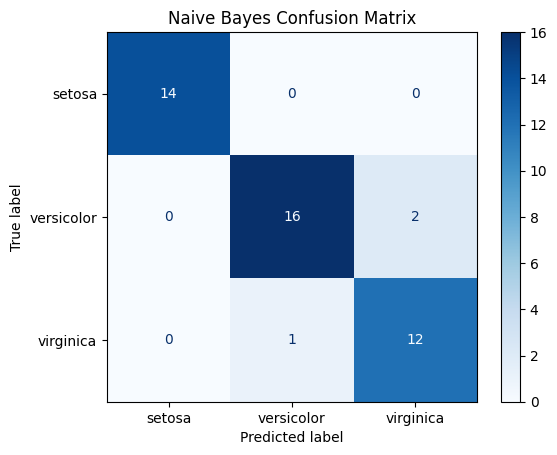

In [8]:

import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import confusion_matrix, accuracy_score, ConfusionMatrixDisplay

# Load dataset
iris = load_iris()
X = iris.data
y = iris.target

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=1
)

# Create and train Naive Bayes model
model = GaussianNB()
model.fit(X_train, y_train)

# Predict output
y_pred = model.predict(X_test)

# Calculate accuracy and confusion matrix
accuracy = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:\n", cm)
print("Accuracy:", round(accuracy * 100, 2), "%")

# Display confusion matrix using Matplotlib
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=iris.target_names
)
display.plot(cmap="Blues")
plt.title("Naive Bayes Confusion Matrix")
plt.show()


Accuracy: 100.0 %


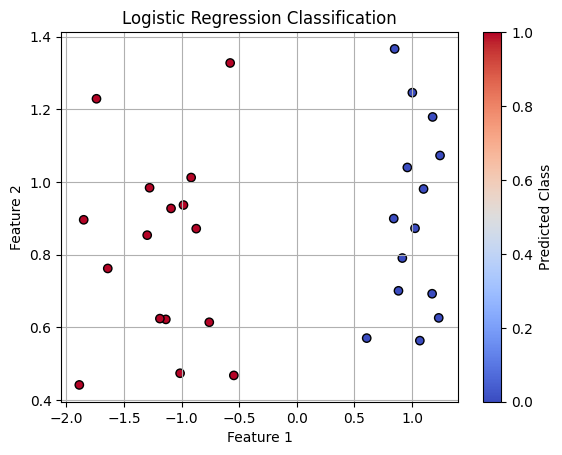

In [9]:

import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.datasets import make_classification

# Create dataset
X, y = make_classification(
    n_samples=100, n_features=2, n_redundant=0,
    n_informative=2, n_clusters_per_class=1,
    random_state=1
)

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=1
)

# Create and train Logistic Regression model
model = LogisticRegression()
model.fit(X_train, y_train)

# Predict output
y_pred = model.predict(X_test)

# Display accuracy
print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")

# Plot classification results
plt.scatter(X_test[:, 0], X_test[:, 1],
            c=y_pred, cmap='coolwarm', edgecolors='black')

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Logistic Regression Classification")
plt.colorbar(label="Predicted Class")
plt.grid(True)
plt.show()


Slope: 0.6
Intercept: 2.2
Predicted values: [2.8 3.4 4.  4.6 5.2]


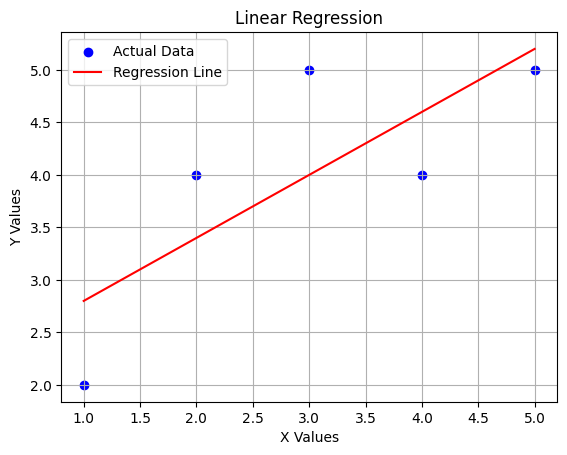

In [10]:

import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
import numpy as np

# Training data
X = np.array([1, 2, 3, 4, 5]).reshape(-1, 1)
y = np.array([2, 4, 5, 4, 5])

# Create and train the model
model = LinearRegression()
model.fit(X, y)

# Predict values
y_pred = model.predict(X)

# Display results
print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)
print("Predicted values:", y_pred)

# Plot the graph
plt.scatter(X, y, color='blue', label='Actual Data')
plt.plot(X, y_pred, color='red', label='Regression Line')

plt.xlabel("X Values")
plt.ylabel("Y Values")
plt.title("Linear Regression")
plt.legend()
plt.grid(True)
plt.show()


Linear Regression MSE: 1.93
Polynomial Regression MSE: 0.22


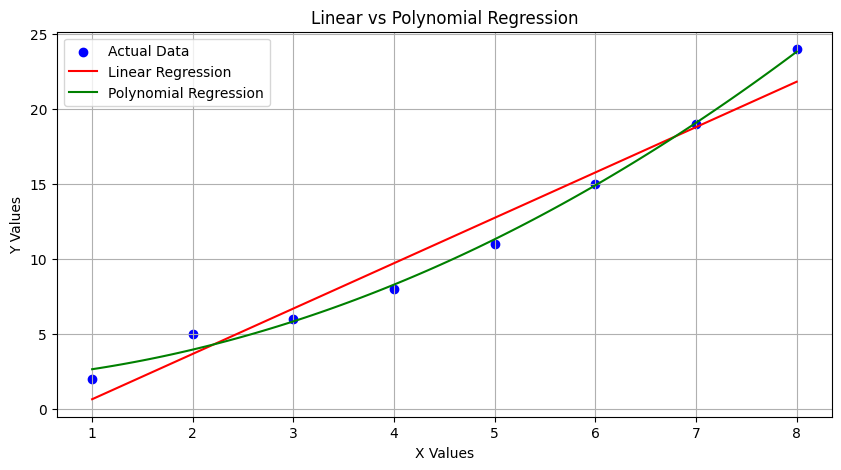

In [11]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error

# Sample dataset
X = np.array([1, 2, 3, 4, 5, 6, 7, 8]).reshape(-1, 1)
y = np.array([2, 5, 6, 8, 11, 15, 19, 24])

# Linear Regression
linear_model = LinearRegression()
linear_model.fit(X, y)
y_linear = linear_model.predict(X)

# Polynomial Regression (degree 2)
poly = PolynomialFeatures(degree=2)
X_poly = poly.fit_transform(X)

poly_model = LinearRegression()
poly_model.fit(X_poly, y)
y_poly = poly_model.predict(X_poly)

# Display errors
print("Linear Regression MSE:",
      round(mean_squared_error(y, y_linear), 2))
print("Polynomial Regression MSE:",
      round(mean_squared_error(y, y_poly), 2))

# Smooth curve for plotting
X_curve = np.linspace(1, 8, 100).reshape(-1, 1)
y_linear_curve = linear_model.predict(X_curve)
y_poly_curve = poly_model.predict(poly.transform(X_curve))

# Plot comparison
plt.figure(figsize=(10, 5))

plt.scatter(X, y, color="blue", label="Actual Data")
plt.plot(X_curve, y_linear_curve, color="red",
         label="Linear Regression")
plt.plot(X_curve, y_poly_curve, color="green",
         label="Polynomial Regression")

plt.xlabel("X Values")
plt.ylabel("Y Values")
plt.title("Linear vs Polynomial Regression")
plt.legend()
plt.grid(True)
plt.show()


Cluster Means:
[[2.88676415]
 [6.99214641]]

Cluster Weights:
[0.49518346 0.50481654]


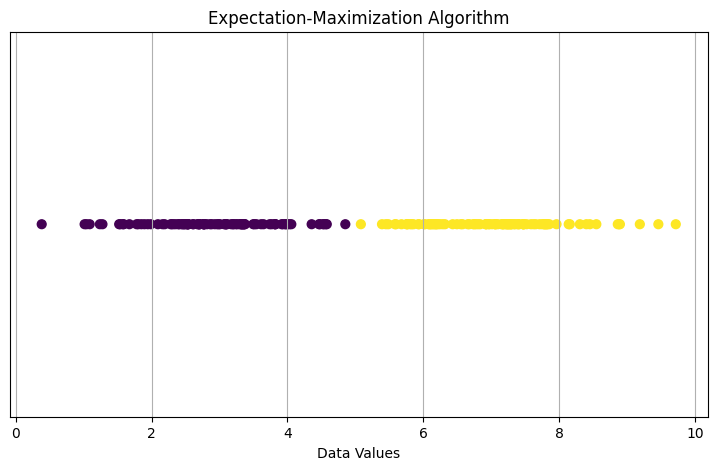

In [12]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.mixture import GaussianMixture

# Generate sample data
np.random.seed(42)

data1 = np.random.normal(3, 1, 100)
data2 = np.random.normal(7, 1, 100)
X = np.concatenate([data1, data2]).reshape(-1, 1)

# Create EM model using Gaussian Mixture
model = GaussianMixture(n_components=2, random_state=42)

# Train the model
model.fit(X)

# Predict clusters
labels = model.predict(X)

# Display cluster means
print("Cluster Means:")
print(model.means_)

# Display cluster probabilities
print("\nCluster Weights:")
print(model.weights_)

# Plot the clusters
plt.figure(figsize=(9, 5))

plt.scatter(X[:, 0], np.zeros(len(X)),
            c=labels, cmap="viridis", s=40)

plt.xlabel("Data Values")
plt.yticks([])
plt.title("Expectation-Maximization Algorithm")
plt.grid(True)
plt.show()


Accuracy: 100.0 %
New Customer Income: 65 thousand
New Customer Debt: 15 thousand
Predicted Class: High Credit Score


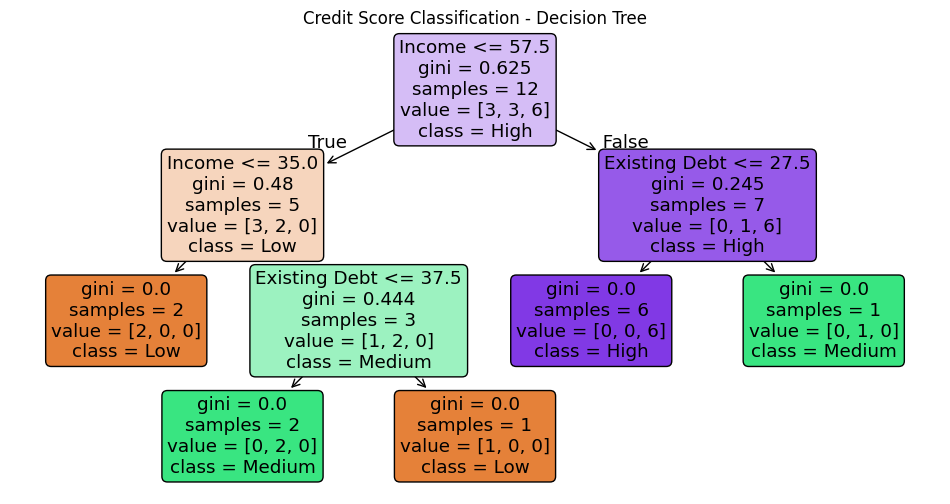

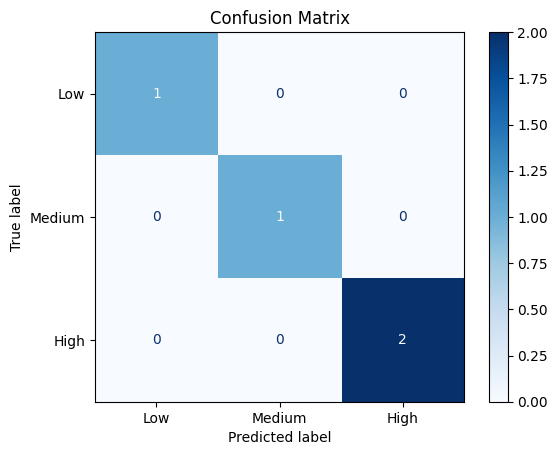

In [13]:

import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# Sample credit score dataset
# Features: Income (in thousands), Existing Debt (in thousands)
X = [
    [25, 20], [30, 25], [35, 30], [40, 35],
    [45, 15], [50, 20], [60, 10], [70, 15],
    [80, 10], [90, 5], [55, 40], [65, 35],
    [75, 20], [85, 15], [95, 10], [100, 5]
]

# Credit score classes: 0 = Low, 1 = Medium, 2 = High
y = [
    0, 0, 0, 1, 1, 1, 2, 2,
    2, 2, 0, 1, 2, 2, 2, 2
]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# Create and train the model
model = DecisionTreeClassifier(max_depth=3, random_state=42)
model.fit(X_train, y_train)

# Predict credit score classes
y_pred = model.predict(X_test)

# Display accuracy
print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")

# Predict for a new customer
new_customer = [[65, 15]]
prediction = model.predict(new_customer)[0]

classes = {0: "Low Credit Score", 1: "Medium Credit Score",
           2: "High Credit Score"}

print("New Customer Income:", new_customer[0][0], "thousand")
print("New Customer Debt:", new_customer[0][1], "thousand")
print("Predicted Class:", classes[prediction])

# Plot 1: Decision Tree
plt.figure(figsize=(12, 6))
plot_tree(
    model,
    feature_names=["Income", "Existing Debt"],
    class_names=["Low", "Medium", "High"],
    filled=True,
    rounded=True
)
plt.title("Credit Score Classification - Decision Tree")
plt.show()

# Plot 2: Confusion Matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1, 2])
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Low", "Medium", "High"]
)
disp.plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.show()


Accuracy: 93.33 %
Predicted Iris Flower: setosa


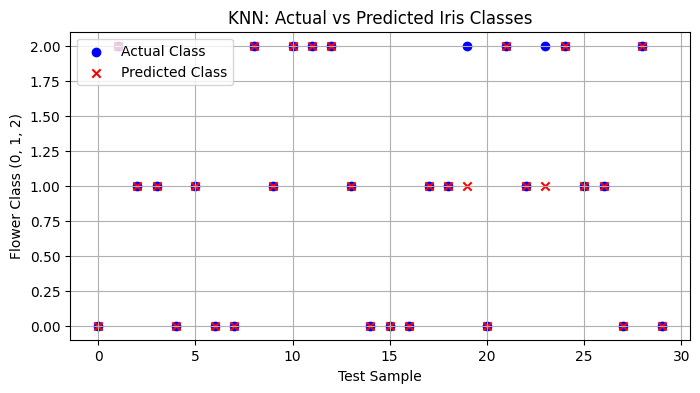

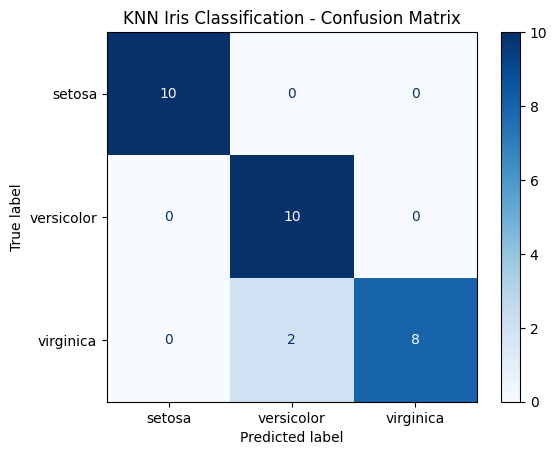

In [14]:

import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# Load Iris dataset
iris = load_iris()
X = iris.data
y = iris.target

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Scale the features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Create and train KNN model
model = KNeighborsClassifier(n_neighbors=5)
model.fit(X_train, y_train)

# Predict flower classes
y_pred = model.predict(X_test)

# Display accuracy
print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")

# Predict a new flower
# Features: sepal length, sepal width, petal length, petal width
new_flower = [[5.1, 3.5, 1.4, 0.2]]
new_flower_scaled = scaler.transform(new_flower)
prediction = model.predict(new_flower_scaled)[0]

print("Predicted Iris Flower:", iris.target_names[prediction])

# Plot 1: Actual vs Predicted classes
plt.figure(figsize=(8, 4))
plt.scatter(range(len(y_test)), y_test, color="blue",
            label="Actual Class", marker="o")
plt.scatter(range(len(y_pred)), y_pred, color="red",
            label="Predicted Class", marker="x")
plt.xlabel("Test Sample")
plt.ylabel("Flower Class (0, 1, 2)")
plt.title("KNN: Actual vs Predicted Iris Classes")
plt.legend()
plt.grid(True)
plt.show()

# Plot 2: Confusion matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=iris.target_names
)
disp.plot(cmap="Blues")
plt.title("KNN Iris Classification - Confusion Matrix")
plt.show()


Mean Absolute Error: 0.2 lakhs
R2 Score: 0.99
Car Age: 4 years
Predicted Car Price: 7.25 lakhs


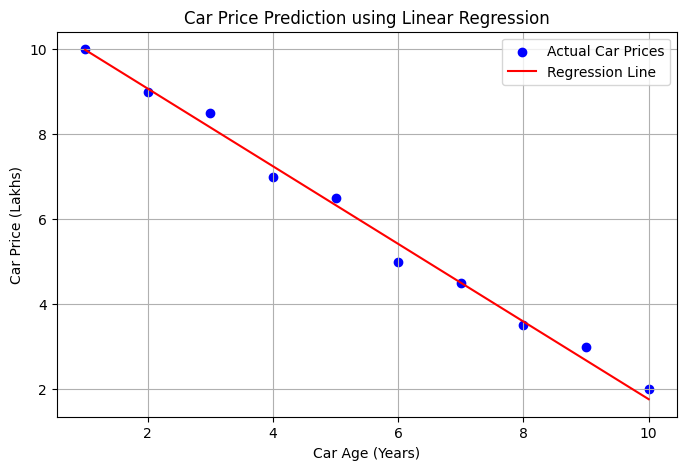

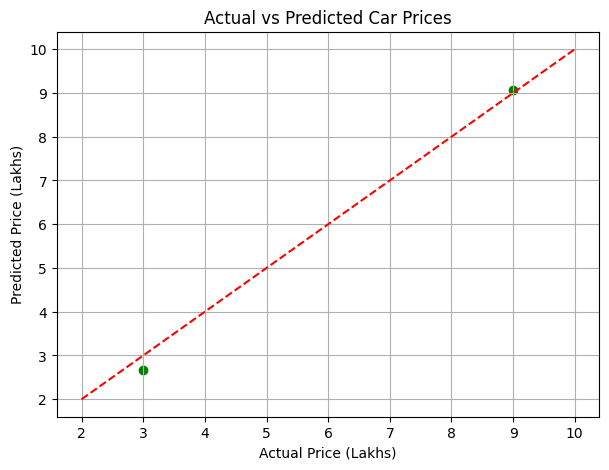

In [15]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score

# Sample dataset
# Car age in years and price in lakhs
X = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9, 10]).reshape(-1, 1)
y = np.array([10, 9, 8.5, 7, 6.5, 5, 4.5, 3.5, 3, 2])

# Split dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create and train the model
model = LinearRegression()
model.fit(X_train, y_train)

# Predict car prices
y_pred = model.predict(X_test)

# Display evaluation results
print("Mean Absolute Error:", round(mean_absolute_error(y_test, y_pred), 2), "lakhs")
print("R2 Score:", round(r2_score(y_test, y_pred), 2))

# Predict the price of a 4-year-old car
car_age = np.array([[4]])
predicted_price = model.predict(car_age)

print("Car Age:", car_age[0][0], "years")
print("Predicted Car Price:", round(predicted_price[0], 2), "lakhs")

# Plot actual data and regression line
X_line = np.linspace(1, 10, 100).reshape(-1, 1)
y_line = model.predict(X_line)

plt.figure(figsize=(8, 5))
plt.scatter(X, y, color="blue", label="Actual Car Prices")
plt.plot(X_line, y_line, color="red", label="Regression Line")

plt.xlabel("Car Age (Years)")
plt.ylabel("Car Price (Lakhs)")
plt.title("Car Price Prediction using Linear Regression")
plt.legend()
plt.grid(True)
plt.show()

# Plot actual vs predicted prices on test data
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred, color="green")
plt.plot([min(y), max(y)], [min(y), max(y)],
         color="red", linestyle="--")

plt.xlabel("Actual Price (Lakhs)")
plt.ylabel("Predicted Price (Lakhs)")
plt.title("Actual vs Predicted Car Prices")
plt.grid(True)
plt.show()


Mean Absolute Error: 0.42 lakhs
R2 Score: 1.0
House Area: 1250 sq.ft
Predicted House Price: 33.91 lakhs


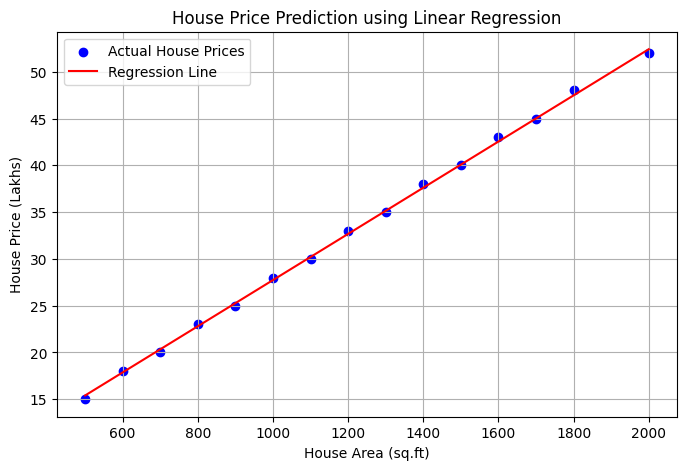

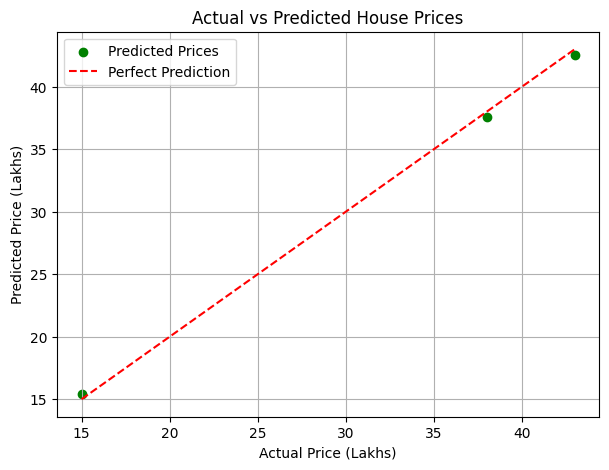

In [16]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score

# Sample dataset
# House area in square feet
X = np.array([
    500, 600, 700, 800, 900,
    1000, 1100, 1200, 1300, 1400,
    1500, 1600, 1700, 1800, 2000
]).reshape(-1, 1)

# House prices in lakhs
y = np.array([
    15, 18, 20, 23, 25,
    28, 30, 33, 35, 38,
    40, 43, 45, 48, 52
])

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create and train the Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Predict house prices
y_pred = model.predict(X_test)

# Display model performance
print("Mean Absolute Error:",
      round(mean_absolute_error(y_test, y_pred), 2), "lakhs")
print("R2 Score:", round(r2_score(y_test, y_pred), 2))

# Predict the price of a new house
area = np.array([[1250]])
predicted_price = model.predict(area)

print("House Area:", area[0][0], "sq.ft")
print("Predicted House Price:",
      round(predicted_price[0], 2), "lakhs")

# Plot actual data and regression line
X_line = np.linspace(500, 2000, 100).reshape(-1, 1)
y_line = model.predict(X_line)

plt.figure(figsize=(8, 5))
plt.scatter(X, y, color="blue", label="Actual House Prices")
plt.plot(X_line, y_line, color="red", label="Regression Line")

plt.xlabel("House Area (sq.ft)")
plt.ylabel("House Price (Lakhs)")
plt.title("House Price Prediction using Linear Regression")
plt.legend()
plt.grid(True)
plt.show()

# Plot actual vs predicted prices
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred, color="green", label="Predicted Prices")

plt.plot(
    [min(y_test), max(y_test)],
    [min(y_test), max(y_test)],
    color="red",
    linestyle="--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Price (Lakhs)")
plt.ylabel("Predicted Price (Lakhs)")
plt.title("Actual vs Predicted House Prices")
plt.legend()
plt.grid(True)
plt.show()


Accuracy: 96.67 %
Predicted Iris Flower: setosa


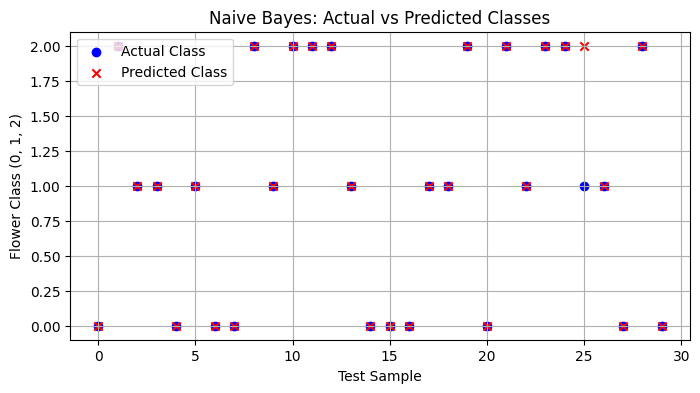

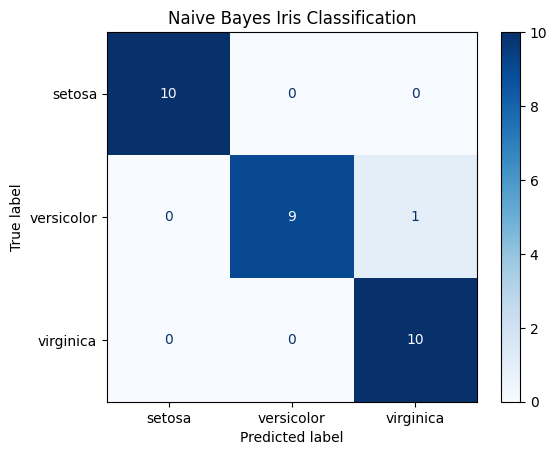

In [17]:

import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# Load Iris dataset
iris = load_iris()
X = iris.data
y = iris.target

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Create and train Naive Bayes model
model = GaussianNB()
model.fit(X_train, y_train)

# Predict flower classes
y_pred = model.predict(X_test)

# Display accuracy
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", round(accuracy * 100, 2), "%")

# Predict a new flower
# Features: sepal length, sepal width, petal length, petal width
new_flower = [[5.1, 3.5, 1.4, 0.2]]
prediction = model.predict(new_flower)[0]

print("Predicted Iris Flower:", iris.target_names[prediction])

# Plot 1: Actual vs Predicted classes
plt.figure(figsize=(8, 4))
plt.scatter(range(len(y_test)), y_test, color="blue",
            label="Actual Class", marker="o")
plt.scatter(range(len(y_pred)), y_pred, color="red",
            label="Predicted Class", marker="x")

plt.xlabel("Test Sample")
plt.ylabel("Flower Class (0, 1, 2)")
plt.title("Naive Bayes: Actual vs Predicted Classes")
plt.legend()
plt.grid(True)
plt.show()

# Plot 2: Confusion matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=iris.target_names
)
disp.plot(cmap="Blues")
plt.title("Naive Bayes Iris Classification")
plt.show()


Classification Algorithm Performance

Logistic Regression
Accuracy: 93.33 %
Precision: 93.33 %
Recall: 93.33 %
F1-Score: 93.33 %

KNN
Accuracy: 93.33 %
Precision: 94.44 %
Recall: 93.33 %
F1-Score: 93.27 %

Decision Tree
Accuracy: 93.33 %
Precision: 93.33 %
Recall: 93.33 %
F1-Score: 93.33 %

Naive Bayes
Accuracy: 96.67 %
Precision: 96.97 %
Recall: 96.67 %
F1-Score: 96.66 %



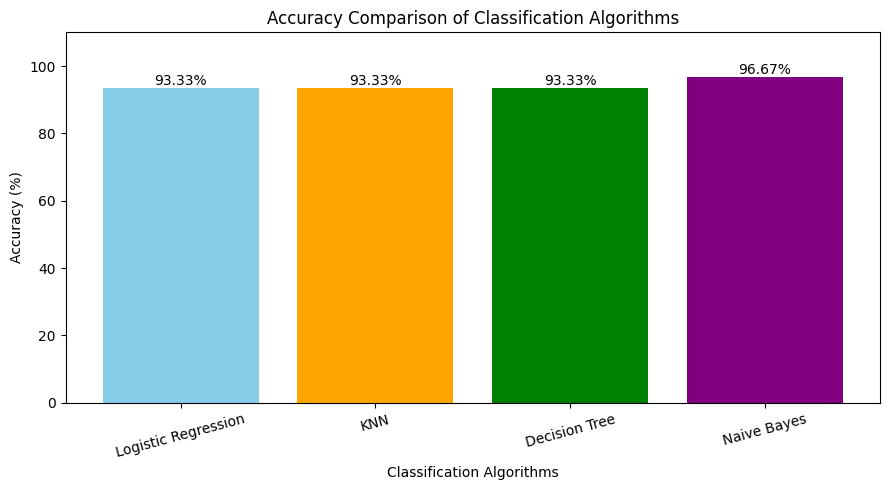

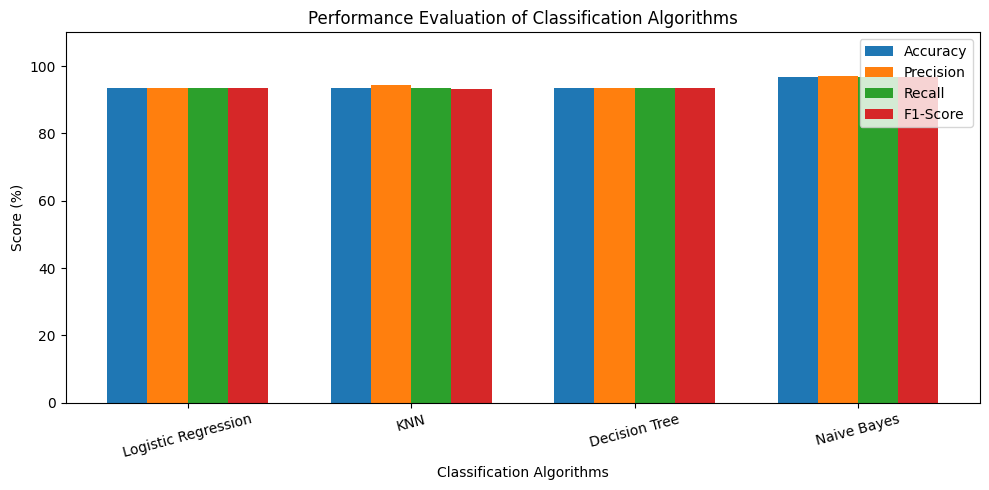

In [18]:

import matplotlib.pyplot as plt
import numpy as np

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Load dataset
iris = load_iris()
X = iris.data
y = iris.target

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Define classification algorithms
models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=1000)
    ),
    "KNN": make_pipeline(
        StandardScaler(), KNeighborsClassifier(n_neighbors=5)
    ),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Naive Bayes": GaussianNB()
}

# Evaluate each algorithm
results = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    results[name] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, average="weighted", zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, average="weighted", zero_division=0
        )
    }

# Print performance results
print("Classification Algorithm Performance\n")

for name, scores in results.items():
    print(name)
    for metric, value in scores.items():
        print(metric + ":", round(value * 100, 2), "%")
    print()

# Plot accuracy comparison
names = list(results.keys())
accuracies = [results[name]["Accuracy"] * 100 for name in names]

plt.figure(figsize=(9, 5))
bars = plt.bar(names, accuracies, color=["skyblue", "orange", "green", "purple"])

plt.xlabel("Classification Algorithms")
plt.ylabel("Accuracy (%)")
plt.title("Accuracy Comparison of Classification Algorithms")
plt.ylim(0, 110)
plt.xticks(rotation=15)

for bar, value in zip(bars, accuracies):
    plt.text(bar.get_x() + bar.get_width() / 2,
             bar.get_height() + 1,
             f"{value:.2f}%", ha="center")

plt.tight_layout()
plt.show()

# Plot all evaluation metrics
metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]
x = np.arange(len(names))
width = 0.18

plt.figure(figsize=(10, 5))

for i, metric in enumerate(metrics):
    values = [results[name][metric] * 100 for name in names]
    plt.bar(x + (i - 1.5) * width, values, width, label=metric)

plt.xlabel("Classification Algorithms")
plt.ylabel("Score (%)")
plt.title("Performance Evaluation of Classification Algorithms")
plt.xticks(x, names, rotation=15)
plt.ylim(0, 110)
plt.legend()
plt.tight_layout()
plt.show()


Accuracy: 100.0 %
New Mobile Specifications: [4096, 4000, 128]
Predicted Price Range: High Price


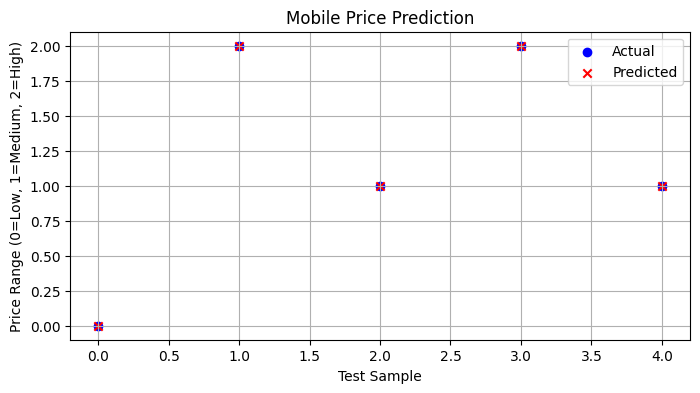

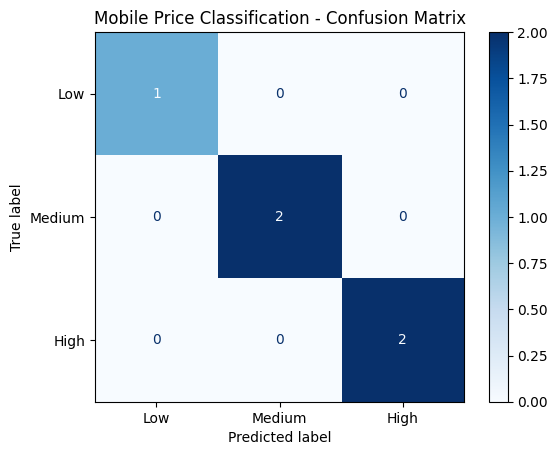

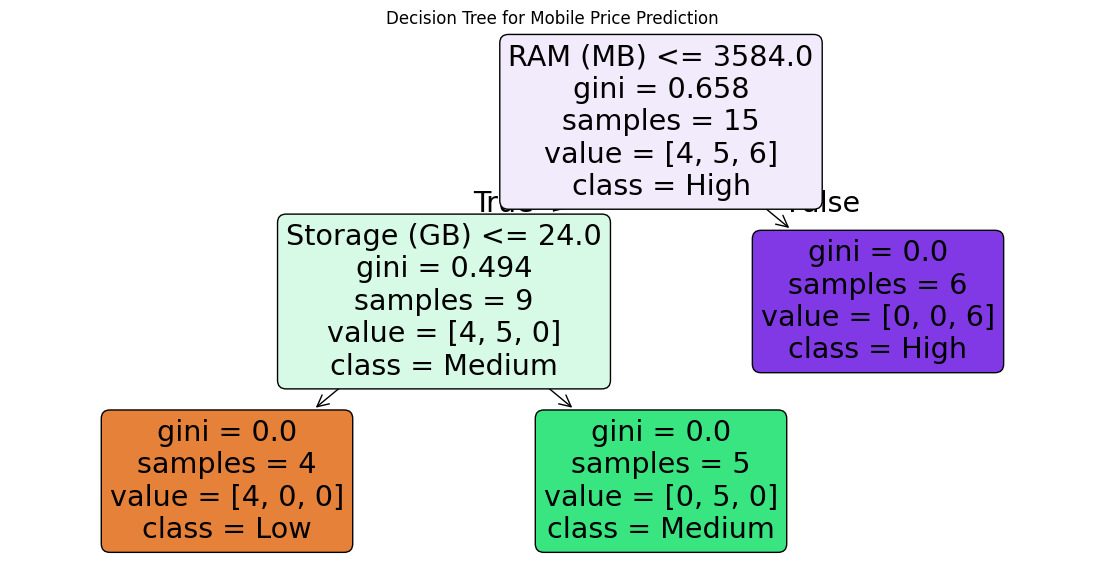

In [19]:

import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay, confusion_matrix

# Sample dataset
# Features: RAM (MB), Battery (mAh), Internal Storage (GB)
X = [
    [512, 2000, 8], [768, 2500, 16], [1024, 3000, 16],
    [1024, 2500, 32], [2048, 3000, 32], [2048, 3500, 64],
    [3072, 3500, 64], [4096, 4000, 64], [4096, 4500, 128],
    [6144, 4500, 128], [8192, 5000, 128], [8192, 5000, 256],
    [1024, 2200, 8], [2048, 3200, 32], [3072, 4000, 64],
    [6144, 4800, 256], [512, 1800, 8], [4096, 4200, 128],
    [8192, 4800, 256], [3072, 3000, 32]
]

# Price ranges: 0 = Low, 1 = Medium, 2 = High
y = [
    0, 0, 0, 1, 1, 1, 1, 2, 2, 2,
    2, 2, 0, 1, 1, 2, 0, 2, 2, 1
]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# Create and train model
model = DecisionTreeClassifier(max_depth=4, random_state=42)
model.fit(X_train, y_train)

# Predict price ranges
y_pred = model.predict(X_test)

# Evaluate model
print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")

# Predict price range for a new mobile
# RAM = 4096 MB, Battery = 4000 mAh, Storage = 128 GB
new_mobile = [[4096, 4000, 128]]
prediction = model.predict(new_mobile)[0]

price_ranges = {0: "Low Price", 1: "Medium Price", 2: "High Price"}
print("New Mobile Specifications:", new_mobile[0])
print("Predicted Price Range:", price_ranges[prediction])

# Plot 1: Actual vs Predicted price ranges
plt.figure(figsize=(8, 4))
plt.scatter(range(len(y_test)), y_test, color="blue",
            label="Actual", marker="o")
plt.scatter(range(len(y_pred)), y_pred, color="red",
            label="Predicted", marker="x")
plt.xlabel("Test Sample")
plt.ylabel("Price Range (0=Low, 1=Medium, 2=High)")
plt.title("Mobile Price Prediction")
plt.legend()
plt.grid(True)
plt.show()

# Plot 2: Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1, 2])
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Low", "Medium", "High"]
)
disp.plot(cmap="Blues")
plt.title("Mobile Price Classification - Confusion Matrix")
plt.show()

# Plot 3: Decision tree
plt.figure(figsize=(14, 7))
plot_tree(
    model,
    feature_names=["RAM (MB)", "Battery (mAh)", "Storage (GB)"],
    class_names=["Low", "Medium", "High"],
    filled=True,
    rounded=True
)
plt.title("Decision Tree for Mobile Price Prediction")
plt.show()


Accuracy: 86.67 %
Predicted Iris Flower: setosa


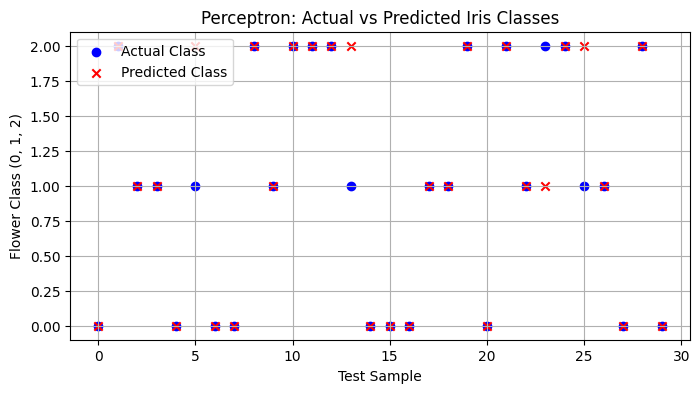

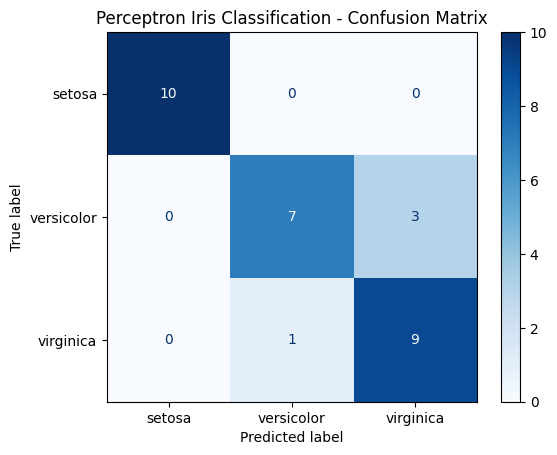

In [20]:

import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Perceptron
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# Load Iris dataset
iris = load_iris()
X = iris.data
y = iris.target

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Create Perceptron model with feature scaling
model = make_pipeline(
    StandardScaler(),
    Perceptron(max_iter=1000, eta0=0.1, random_state=42)
)

# Train the model
model.fit(X_train, y_train)

# Predict flower classes
y_pred = model.predict(X_test)

# Display accuracy
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", round(accuracy * 100, 2), "%")

# Predict a new flower
# Features: sepal length, sepal width, petal length, petal width
new_flower = [[5.1, 3.5, 1.4, 0.2]]
prediction = model.predict(new_flower)[0]

print("Predicted Iris Flower:", iris.target_names[prediction])

# Plot 1: Actual vs Predicted classes
plt.figure(figsize=(8, 4))
plt.scatter(range(len(y_test)), y_test, color="blue",
            label="Actual Class", marker="o")
plt.scatter(range(len(y_pred)), y_pred, color="red",
            label="Predicted Class", marker="x")

plt.xlabel("Test Sample")
plt.ylabel("Flower Class (0, 1, 2)")
plt.title("Perceptron: Actual vs Predicted Iris Classes")
plt.legend()
plt.grid(True)
plt.show()

# Plot 2: Confusion matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=iris.target_names
)
disp.plot(cmap="Blues")
plt.title("Perceptron Iris Classification - Confusion Matrix")
plt.show()


Accuracy: 100.0 %
Predicted Loan Status: Approved


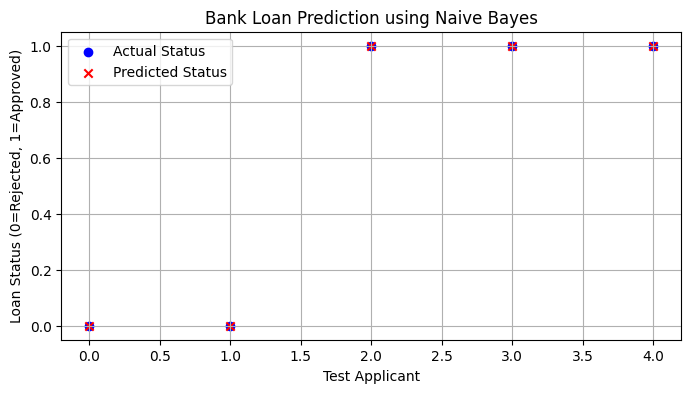

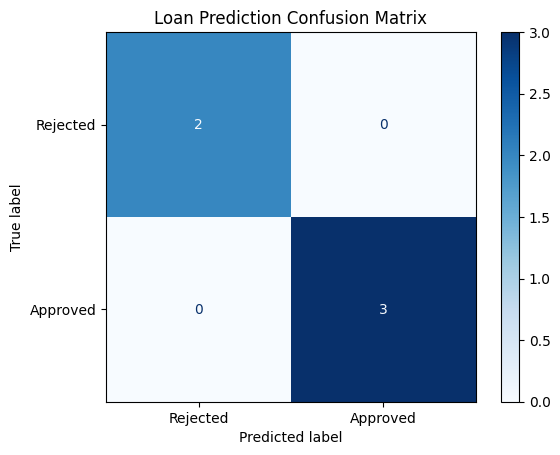

In [21]:

import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# Sample dataset
# Features: Income (in thousands), Credit Score, Loan Amount (in thousands)
X = [
    [25, 600, 100], [30, 650, 120], [35, 700, 150],
    [40, 720, 100], [45, 750, 180], [50, 780, 200],
    [28, 580, 150], [32, 620, 100], [38, 680, 130],
    [55, 800, 220], [60, 820, 250], [65, 850, 200],
    [22, 550, 180], [48, 760, 150], [70, 870, 300],
    [33, 640, 200], [58, 810, 180], [42, 730, 120],
    [75, 890, 250], [27, 590, 120]
]

# Loan status: 0 = Rejected, 1 = Approved
y = [
    0, 0, 1, 1, 1, 1, 0, 0, 1, 1,
    1, 1, 0, 1, 1, 0, 1, 1, 1, 0
]

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# Create and train Naive Bayes model
model = GaussianNB()
model.fit(X_train, y_train)

# Predict loan status
y_pred = model.predict(X_test)

# Display accuracy
print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")

# Predict for a new applicant
# Income = 50, Credit Score = 780, Loan Amount = 150
new_applicant = [[50, 780, 150]]
prediction = model.predict(new_applicant)[0]

if prediction == 1:
    print("Predicted Loan Status: Approved")
else:
    print("Predicted Loan Status: Rejected")

# Plot 1: Actual vs Predicted loan status
plt.figure(figsize=(8, 4))
plt.scatter(range(len(y_test)), y_test, color="blue",
            label="Actual Status", marker="o")
plt.scatter(range(len(y_pred)), y_pred, color="red",
            label="Predicted Status", marker="x")

plt.xlabel("Test Applicant")
plt.ylabel("Loan Status (0=Rejected, 1=Approved)")
plt.title("Bank Loan Prediction using Naive Bayes")
plt.legend()
plt.grid(True)
plt.show()

# Plot 2: Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Rejected", "Approved"]
)
disp.plot(cmap="Blues")
plt.title("Loan Prediction Confusion Matrix")
plt.show()


Mean Absolute Error: 0.15
R2 Score: 1.0

Future Sales Prediction:
Month 13 : 44.16 thousand
Month 14 : 46.2 thousand
Month 15 : 48.24 thousand


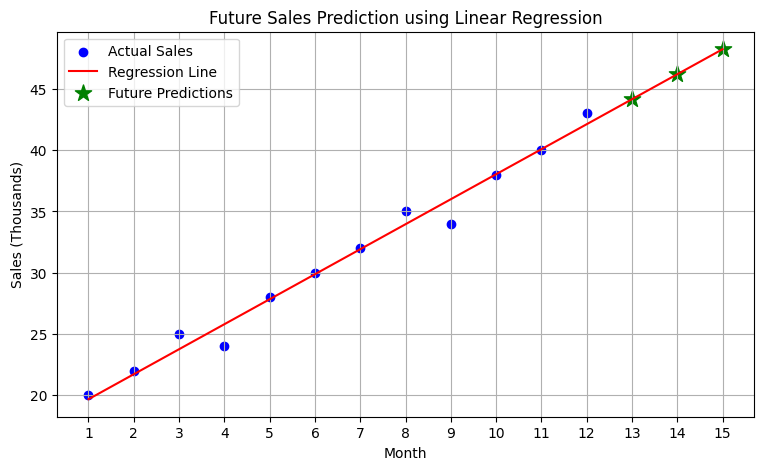

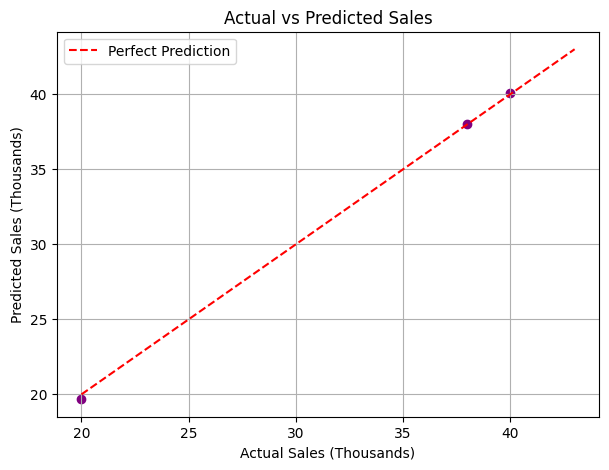

In [22]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score

# Sample dataset: Month and Sales
months = np.array([
    1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12
]).reshape(-1, 1)

# Sales in thousands
sales = np.array([
    20, 22, 25, 24, 28, 30, 32, 35, 34, 38, 40, 43
])

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    months, sales, test_size=0.2, random_state=42
)

# Create and train the Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Predict sales for test data
y_pred = model.predict(X_test)

# Evaluate model
print("Mean Absolute Error:",
      round(mean_absolute_error(y_test, y_pred), 2))
print("R2 Score:", round(r2_score(y_test, y_pred), 2))

# Predict future sales for the next 3 months
future_months = np.array([13, 14, 15]).reshape(-1, 1)
future_sales = model.predict(future_months)

print("\nFuture Sales Prediction:")
for month, sale in zip(future_months.flatten(), future_sales):
    print("Month", month, ":", round(sale, 2), "thousand")

# Plot actual sales and regression line
all_months = np.arange(1, 16).reshape(-1, 1)
predicted_sales = model.predict(all_months)

plt.figure(figsize=(9, 5))
plt.scatter(months, sales, color="blue", label="Actual Sales")
plt.plot(all_months, predicted_sales, color="red",
         label="Regression Line")
plt.scatter(future_months, future_sales, color="green",
            marker="*", s=150, label="Future Predictions")

plt.xlabel("Month")
plt.ylabel("Sales (Thousands)")
plt.title("Future Sales Prediction using Linear Regression")
plt.xticks(range(1, 16))
plt.legend()
plt.grid(True)
plt.show()

# Plot actual vs predicted sales for test data
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred, color="purple")

plt.plot(
    [min(sales), max(sales)],
    [min(sales), max(sales)],
    color="red", linestyle="--", label="Perfect Prediction"
)

plt.xlabel("Actual Sales (Thousands)")
plt.ylabel("Predicted Sales (Thousands)")
plt.title("Actual vs Predicted Sales")
plt.legend()
plt.grid(True)
plt.show()
